# Topic Modeling
Unsupervised topic discovery on YouTube crisis comments using BERTopic.

## Methodology

### Motivation
After scoring comments by sentiment, we apply topic modeling to uncover
*what* people are talking about — blame attribution, calls for justice,
grief, misinformation, political critique — giving qualitative structure
to the quantitative sentiment scores.

### Approach
We use **BERTopic** — an embedding-based topic model that:
1. Encodes each comment into a dense vector (sentence-transformers)
2. Reduces dimensionality (UMAP) for clustering stability
3. Clusters semantically similar comments (HDBSCAN)
4. Extracts descriptive terms per cluster (c-TF-IDF)

### Pipeline

| Phase | Step | Description |
|---|---|---|
| **1. Preprocessing** | Text cleaning | Lowercase, strip punctuation/URLs/digits, remove English + Filipino stopwords |
| **2. Embedding** | Sentence vectors | `paraphrase-multilingual-MiniLM-L12-v2` (12 languages, 384-d) |
| **3. Reduction** | UMAP | 384-d → 5-d for density-based clustering |
| **4. Clustering** | HDBSCAN | Soft clustering; non-assigned → noise cluster (-1) |
| **5. Representation** | c-TF-IDF | Top unigrams/bigrams per cluster as topic descriptors |
| **6. Labeling** | Manual annotation | Human-readable labels from top terms + sample comments |

### Cross-Analysis
Topic assignments are joined with sentiment labels, shouting flags,
and video IDs to answer:
- *Which topics dominate each news source?*
- *Do certain topics carry more negative sentiment?*
- *Are shouted comments concentrated in specific topics?*

### Input / Output
- **Input:** `scored_{BATCH_NAME}.csv` from sentiment analysis
- **Output:** Topic-labeled DataFrame + per-video topic profile + topic × sentiment cross-tab

In [81]:
import pandas as pd
import numpy as np
import ast
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""
import re
import string
import nltk

from nltk.corpus import stopwords
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer

import spacy

from dotenv import load_dotenv
from google import genai
from google.genai import types

import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.dpi"] = 150

## Configuration
Batch selector. Change `BATCH_NAME` to switch between
`youtube_comments_batch_{1,2,3}.csv`.

In [82]:
# --- CONFIG ---
BASE_DIR = "../output"
BATCH_NAME = "scored_06-townhall_podcast.csv"
BATCH_PATH = os.path.join(BASE_DIR, BATCH_NAME)

## Load Batch
Read the scored CSV. Each row is a cleaned comment with
`sentiment_label`, `sentiment_score`, `is_shouting`, and
`sentences`. These features feed into cross-analysis
after topic modeling.

In [83]:
batch_df = pd.read_csv(BATCH_PATH)
print(f"Loaded {len(batch_df)} comments from {BATCH_NAME}")

# Parse the sentences column from stringified list back to Python list
batch_df['sentences'] = batch_df['sentences'].apply(ast.literal_eval)

batch_df[["text", "sentiment_label", "sentiment_score", "is_shouting"]].head()


Loaded 5135 comments from scored_06-townhall_podcast.csv


,text,sentiment_label,sentiment_score,is_shouting
0,kahit maglaro pa sa uaap ang ateneo de satanas...,NEGATIVE,0.870155,0
1,:angry_face::angry_face::angry_face:,NEGATIVE,0.898818,0
2,aksidente nalunod?? me maniniwala ba sainio? p...,NEGATIVE,0.867925,0
3,why talk to pia instead of talking to the pare...,NEGATIVE,0.822589,0
4,mga sinungaling!,NEGATIVE,0.911545,0


## Stopwords

Three sources merged into one set:

| Source | Provides | Origin |
|---|---|---|
| **nltk** | ~179 English stopwords | `nltk.corpus.stopwords` |
| **calamanCy** | ~147 Tagalog stopwords | spaCy defaults from `tl_calamancy_md` |
| **Custom** | ~30 noise words | `po`, `opo`, `kasi`, `lang`, `yung`, `nung`, etc. |

Custom additions cover common comment filler that isn't in
standard stopword lists.


In [84]:
nltk.download("stopwords", quiet=True)

en_stop = set(stopwords.words("english"))
nlp_tl = spacy.load("tl_calamancy_md")
tl_stop = nlp_tl.Defaults.stop_words

custom_stop = {
    "po", "opo", "kasi", "eh", "ah", "oh", "talaga", "naman",
    "lang", "pa", "na", "din", "rin", "raw", "daw", "yung",
    "nung", "sya", "ung", "ng", "sa", "ako", "ikaw", "tayo",
    "niya", "natin", "sila", "amin", "atin",
}

STOPWORDS = en_stop | tl_stop | custom_stop
print(f"Stopwords: {len(STOPWORDS)} total")
print(f"  English:  {len(en_stop)}")
print(f"  Tagalog:  {len(tl_stop)}")
print(f"  Custom:   {len(custom_stop)}")
print(f"Sample TL: {sorted(tl_stop)[:10]}")


Stopwords: 359 total
  English:  198
  Tagalog:  147
  Custom:   29
Sample TL: ['akin', 'aking', 'ako', 'alin', 'am', 'amin', 'aming', 'ang', 'ano', 'anumang']


## Text Cleaning

Apply a lightweight cleaning pipeline for topic modeling:

- Lowercase
- Remove URLs
- Strip punctuation
- Remove digits
- Filter stopwords + tokens shorter than 3 characters

Cleaned text is stored in a new `text_clean` column.
The original `text` column is preserved.


In [85]:
def clean_for_topics(text: str) -> str:
    text = text.lower()
    text = re.sub(r"https?://\S+", "", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", "", text)
    tokens = [w for w in text.split() if w not in STOPWORDS and len(w) > 2]
    return " ".join(tokens)

batch_df["text"] = batch_df["text"].fillna("")

batch_df["text_clean"] = batch_df["text"].apply(clean_for_topics)
corpus = batch_df["text_clean"].tolist()

print(f"Corpus: {len(corpus)} documents")
print(f"Avg tokens/doc before: {np.mean([len(t.split()) for t in batch_df['text']]):.0f}")
print(f"Avg tokens/doc after:  {np.mean([len(t.split()) for t in corpus]):.0f}")


Corpus: 5135 documents
Avg tokens/doc before: 35
Avg tokens/doc after:  18


## Embeddings

Encode each cleaned comment into a dense vector using
`sentence-transformers` for semantic clustering.

### Model

`paraphrase-multilingual-MiniLM-L12-v2` — chosen because:
- **Multilingual**: supports English + Tagalog + code-switched text
- **384-dimensional**: compact enough for UMAP reduction
- **Sentence-level**: trained on NLI/STS pairs for semantic similarity
  (critical for BERTopic's clustering quality)


In [86]:
EMBEDDING_MODEL = "paraphrase-multilingual-MiniLM-L12-v2"
embedding_model = SentenceTransformer(EMBEDDING_MODEL)

print(f"Encoding {len(corpus)} documents with {EMBEDDING_MODEL}...")
embeddings = embedding_model.encode(
    corpus,
    show_progress_bar=True,
    batch_size=64,
)
print(f"Embedding shape: {embeddings.shape}")


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3987.48it/s]


Encoding 5135 documents with paraphrase-multilingual-MiniLM-L12-v2...


Batches: 100%|██████████| 81/81 [00:41<00:00,  1.94it/s]


Embedding shape: (5135, 384)


## BERTopic Model

Fit the topic model on the precomputed embeddings.

### Pipeline

| Step | Component | What it does |
|---|---|---|
| **1. Reduce** | UMAP (n_neighbors=15, n_components=5) | 384-d → 5-d for clustering stability |
| **2. Cluster** | HDBSCAN (min_cluster_size=10) | Density-based; unassigned → noise (-1) |
| **3. Reduce to 10** | BERTopic merge | Merges smaller topics into nearest larger topic until 10 remain (excl. noise) |
| **4. Represent** | c-TF-IDF | Top terms per cluster as topic descriptors |

### Why HDBSCAN over K-means?

| K-means | HDBSCAN (chosen) |
|---|---|
| Must set `k` upfront | Automatic — finds dense regions |
| Forces every point into a cluster | Noise cluster for off-topic comments |
| Spherical clusters only | Any shape (density-connected) |

For crisis comments, we don’t know the number of themes ahead of time.
HDBSCAN naturally finds them and isolates noise (spam, single-word comments).

### How HDBSCAN Works

Hierarchical Density-Based Spatial Clustering of Applications with Noise.

1. **Build a mutual reachability graph** — each comment (5-d UMAP point)
   is connected to its nearest neighbors. Dense regions get tight connections,
   sparse regions get loose ones.

2. **Create a hierarchy** — edges are removed in order of decreasing distance,
   producing a dendrogram of clusters at every density threshold.

3. **Extract stable clusters** — the algorithm selects clusters that persist
   across a wide range of density thresholds. Fluctuating clusters are pruned;
   only robust groupings remain.

4. **Assign noise** — points that never form a stable cluster are labeled `-1`.

### Why This Matters for Crisis Comments

| Property | Effect |
|---|---|
| **No fixed `k`** | HDBSCAN finds natural clusters; `nr_topics=10` merges smaller topics into the 10 most coherent |
| **Noise handling** | Spam, single words, or off-topic comments → `-1` instead of polluting a real topic |
| **Variable density** | Some themes are tight (e.g., “RIP” comments), others diffuse (e.g., “political critique”) — HDBSCAN handles both |
| **Outlier tolerance** | A heated comment with unusual vocabulary doesn’t force a new cluster or distort an existing one |

In [87]:
topic_model = BERTopic(
    embedding_model=embedding_model,
    min_topic_size=10,
    nr_topics=10,
    verbose=True,
)

topics, probs = topic_model.fit_transform(corpus, embeddings)

n_topics = len(set(topics)) - (1 if -1 in topics else 0)
n_noise = sum(1 for t in topics if t == -1)
print(f"\nTopics found: {n_topics}")
print(f"Noise cluster (-1): {n_noise} comments ({n_noise / len(topics):.1%})")


2026-06-24 15:02:02,675 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-06-24 15:02:22,360 - BERTopic - Dimensionality - Completed ✓
2026-06-24 15:02:22,361 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-06-24 15:02:22,489 - BERTopic - Cluster - Completed ✓
2026-06-24 15:02:22,490 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-06-24 15:02:22,607 - BERTopic - Representation - Completed ✓
2026-06-24 15:02:22,608 - BERTopic - Topic reduction - Reducing number of topics
2026-06-24 15:02:22,629 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-06-24 15:02:22,730 - BERTopic - Representation - Completed ✓
2026-06-24 15:02:22,732 - BERTopic - Topic reduction - Reduced number of topics from 66 to 10



Topics found: 9
Noise cluster (-1): 1950 comments (38.0%)


In [88]:
topic_model.get_topic_info().head(15)


,Topic,Count,Name,Representation,Representative_Docs
0,-1,1950,-1_rene_coach_yan_wala,"[rene, coach, yan, wala, divine, team, players...",[fault players yan sumusnod proseso trainings ...
1,0,915,0_players_coach_rene_rip,"[players, coach, rene, rip, swim, training, st...",[watched interview two honestly stories place ...
2,1,836,1_rene_kayo_nyo_divine,"[rene, kayo, nyo, divine, niyo, yan, mag, nag,...","[niyo kayo mag salita, boys i’m dumb think lik..."
3,2,408,2_trauma_justice_rene_god,"[trauma, justice, rene, god, boys, hope, kids,...",[boys describing traumatic event people social...
4,3,401,3_agree_alas_yan_rene,"[agree, alas, yan, rene, sana, utak, true, kau...",[daming makikitig utak nakikita kadalasang mak...
5,4,346,4_interview_podcast_drone_video,"[interview, podcast, drone, video, rene, nag, ...","[hmbreally cidg nagpa interview podcast come, ..."
6,5,229,5_people_truth_like_you,"[people, truth, like, you, accident, re, fake,...",[cban spare lectures acting like know every si...
7,6,24,6_foldedhandsfoldedhandsfoldedhandsfoldedhands...,"[foldedhandsfoldedhandsfoldedhandsfoldedhands,...",[foldedhandsfoldedhandsfoldedhandsfoldedhands ...
8,7,13,7_boys_well_young_salute,"[boys, well, young, salute, men, speaking, tha...",[well well well news update cidg says sumthin ...
9,8,13,8_earthquake_mindanao_tsunami_effect,"[earthquake, mindanao, tsunami, effect, sudden...",[god bless boys redheart foldedhands think hap...


In [89]:
topic_model.visualize_barchart(top_n_topics=10, n_words=10)


In [90]:
topic_model.visualize_distribution(probs, min_probability=0.05)


## Topic Labeling

Each topic cluster is labeled by `gemma-4-31b-it` via the Gemini API.
Top 10 c-TF-IDF terms + 5 sample comments are sent per topic.
Labels are reviewed and manually overridden as needed.


In [91]:
load_dotenv("../../.env")
client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

MODEL = "gemma-4-31b-it"

LLM_LABELS = {}
for topic_id in sorted([t for t in set(topics) if t != -1]):
    terms = topic_model.get_topic(topic_id)
    term_str = ", ".join([t[0] for t in terms[:10]])

    mask = [t == topic_id for t in topics]
    samples = batch_df.loc[mask, "text"].sample(min(5, sum(mask))).tolist()

    prompt = (
        "You are a crisis discourse analyst. Given the top terms "
        "and sample comments for a topic cluster, assign a short "
        "label (2-4 words).\n\n"
        f"Top terms: {term_str}\n"
        "Sample comments:\n"
        + "\n".join(f"- {s[:200]}" for s in samples[:5])
        + "\n\nLabel (2-4 words):"
    )

    response = client.models.generate_content(
        model=MODEL,
        contents=prompt,
        config=types.GenerateContentConfig(temperature=0),
    )
    label = response.text.strip()
    LLM_LABELS[topic_id] = label
    print(f"Topic {topic_id}: {label}")


Topic 0: Training Negligence Allegations
Topic 1: Rene and Divine Tragedy
Topic 2: Trauma and Accountability
Topic 3: Skepticism and Mockery
Topic 4: Podcast Interview Controversy
Topic 5: Truth and Accountability
Topic 6: Prayer for Truth
Topic 7: Young Men's Investigation
Topic 8: Mindanao Earthquake Tsunami


In [92]:
# Manual label overrides — fix typos or rename topics
# Uncomment and edit lines below, then re-run from here:
LABEL_OVERRIDES = {
    # 3: "Coach Accountability",
    # 5: "Demand for Justice (corrected)",
}

LLM_LABELS.update(LABEL_OVERRIDES)
FINAL_LABELS = LLM_LABELS.copy()

for tid, label in sorted(FINAL_LABELS.items()):
    print(f"  Topic {tid}: {label}")


  Topic 0: Training Negligence Allegations
  Topic 1: Rene and Divine Tragedy
  Topic 2: Trauma and Accountability
  Topic 3: Skepticism and Mockery
  Topic 4: Podcast Interview Controversy
  Topic 5: Truth and Accountability
  Topic 6: Prayer for Truth
  Topic 7: Young Men's Investigation
  Topic 8: Mindanao Earthquake Tsunami


In [93]:
batch_df["topic_id"] = topics
batch_df["topic_label"] = batch_df["topic_id"].map(FINAL_LABELS)
batch_df[["text_clean", "topic_id", "topic_label"]].head(10)


,text_clean,topic_id,topic_label
0,maglaro uaap ateneo satanas este ateneo manila...,-1,NaN
1,angryfaceangryfaceangryface,-1,NaN
2,aksidente nalunod maniniwala sainio nio maitat...,-1,NaN
3,talk pia instead talking pare deceased athletes,-1,NaN
4,sinungaling,3,Skepticism and Mockery
5,tinuloy tuloy dun icpr every second counts gan...,-1,NaN
6,nako pag elite naratives inuuna kysa malaman k...,4,Podcast Interview Controversy
7,dlsu adamson also suspended past ateneo given ...,2,Trauma and Accountability
8,napakasarao pag uumpugin ulo players natonalun...,0,Training Negligence Allegations
9,funny you’ve got time words ready interviews “...,5,Truth and Accountability


## Cross-Analysis

Topic labels are joined with sentiment, shouting, and video metadata
to answer the research questions from the methodology:

- *Which topics dominate each news source (video_id)?*
  → Per-video topic distribution (crosstab + stacked bar)

- *Do certain topics carry more negative sentiment?*
  → Topic × sentiment_label heatmap

- *Are shouted comments concentrated in specific topics?*
  → Shouting ratio per topic


In [94]:
topic_x_video = pd.crosstab(
    batch_df["topic_label"],
    batch_df["video_id"],
    margins=True,
    margins_name="Total",
)
topic_x_video


video_id,0aLkuhqg-tA,1YDO8_FtZYA,SzSL93G_M1w,sCMs_rqURe4,zOFwBifpBV8,Total
topic_label,,,,,,
Mindanao Earthquake Tsunami,0,0,10,1,2,13
Podcast Interview Controversy,16,10,289,9,22,346
Prayer for Truth,0,6,17,0,1,24
Rene and Divine Tragedy,12,77,630,33,84,836
Skepticism and Mockery,9,23,323,9,37,401
Training Negligence Allegations,15,38,723,38,101,915
Trauma and Accountability,5,29,346,12,16,408
Truth and Accountability,4,6,206,5,8,229
Young Men's Investigation,0,0,12,0,1,13


In [95]:
topic_x_sentiment = pd.crosstab(
    batch_df["topic_label"],
    batch_df["sentiment_label"],
    margins=True,
    margins_name="Total",
)
topic_x_sentiment


sentiment_label,NEGATIVE,NEUTRAL,POSITIVE,Total
topic_label,,,,
Mindanao Earthquake Tsunami,9,3,1,13
Podcast Interview Controversy,207,126,13,346
Prayer for Truth,8,13,3,24
Rene and Divine Tragedy,608,169,59,836
Skepticism and Mockery,220,135,45,400
Training Negligence Allegations,751,127,37,915
Trauma and Accountability,314,38,56,408
Truth and Accountability,177,46,6,229
Young Men's Investigation,3,3,7,13


In [96]:
shouting_by_topic = batch_df.groupby("topic_label")["is_shouting"].agg(
    total="count",
    shouted="sum",
)
shouting_by_topic["shouting_ratio"] = shouting_by_topic["shouted"] / shouting_by_topic["total"]
shouting_by_topic.sort_values("shouting_ratio", ascending=False)


,total,shouted,shouting_ratio
topic_label,,,
Skepticism and Mockery,401,17,0.042394
Podcast Interview Controversy,346,14,0.040462
Rene and Divine Tragedy,836,33,0.039474
Truth and Accountability,229,7,0.030568
Training Negligence Allegations,915,17,0.018579
Trauma and Accountability,408,7,0.017157
Mindanao Earthquake Tsunami,13,0,0.000000
Prayer for Truth,24,0,0.000000
Young Men's Investigation,13,0,0.000000


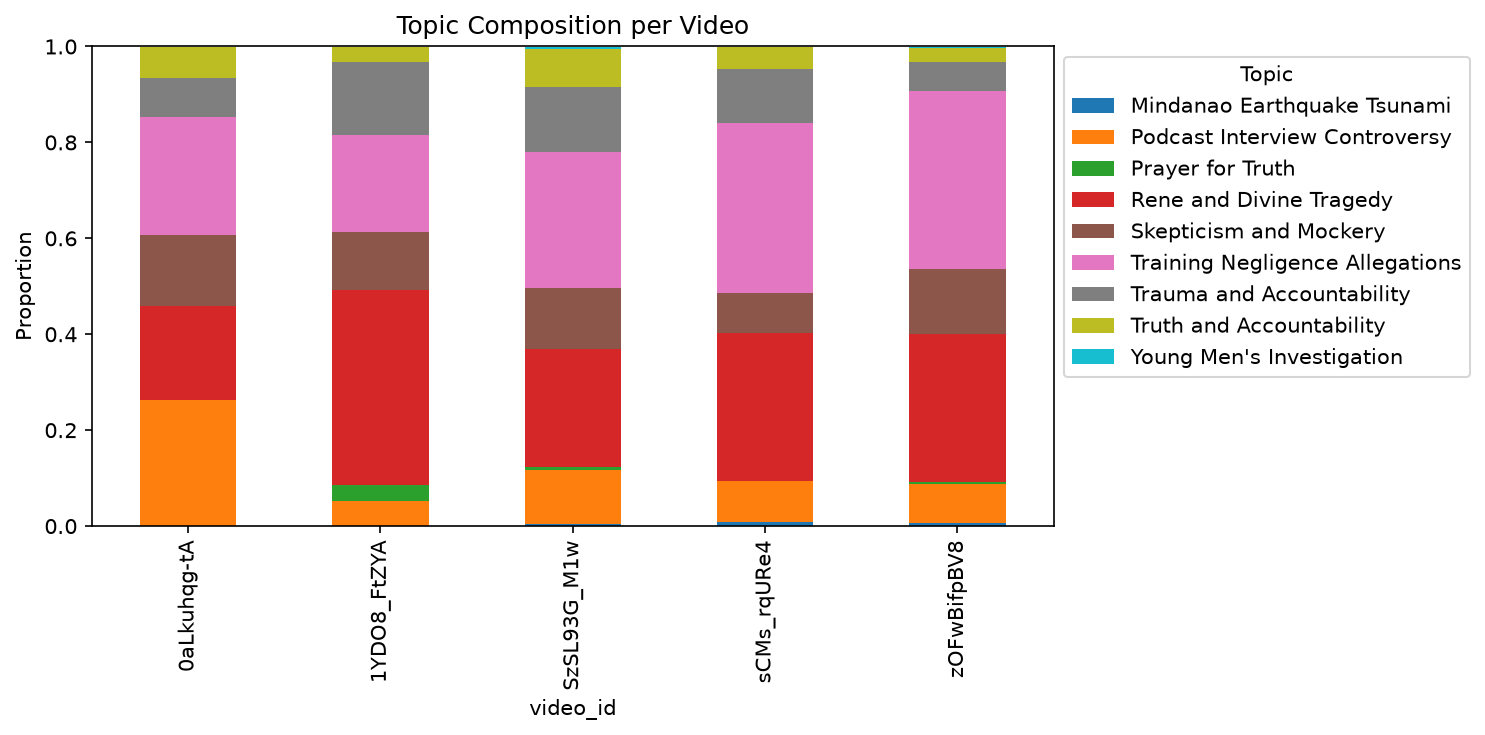

In [97]:
topic_video_pct = (
    batch_df.groupby(["video_id", "topic_label"])
    .size()
    .unstack(fill_value=0)
)
topic_video_pct = topic_video_pct.div(topic_video_pct.sum(axis=1), axis=0)

ax = topic_video_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    colormap="tab10",
)
plt.ylabel("Proportion")
plt.title("Topic Composition per Video")
plt.legend(title="Topic", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()


## Export

Save the topic-labeled comments for downstream use or
comparison across batches.

Columns preserved: text, video_id, sentiment_label, sentiment_score,
is_shouting, topic_id, topic_label, sentences.


In [98]:
output_dir = "../output"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, f"topics_{BATCH_NAME.replace('scored_', '')}")
batch_df.to_csv(output_path, index=False)
print(f"Exported {len(batch_df)} topic-labeled comments to {output_path}")


Exported 5135 topic-labeled comments to ../output/topics_06-townhall_podcast.csv


In [99]:
# Post-hoc topic rename — edit labels in the exported CSV
# Run this cell after export to fix typos without re-running the pipeline.
df = pd.read_csv(output_path)

current = df[["topic_id", "topic_label"]].drop_duplicates().sort_values("topic_id")
display(current)

LABEL_RENAMES = {
    # 0: "Drowning Accountability (corrected)",
}

for tid, label in LABEL_RENAMES.items():
    df.loc[df["topic_id"] == tid, "topic_label"] = label

df.to_csv(output_path, index=False)
print("Labels updated in CSV.")


,topic_id,topic_label
0,-1,NaN
8,0,Training Negligence Allegations
12,1,Rene and Divine Tragedy
7,2,Trauma and Accountability
4,3,Skepticism and Mockery
6,4,Podcast Interview Controversy
9,5,Truth and Accountability
563,6,Prayer for Truth
237,7,Young Men's Investigation
620,8,Mindanao Earthquake Tsunami


Labels updated in CSV.
